# Лабораторна робота № 2

**Дисципліна:** Інтелектуальний аналіз даних

**Тема:** Зменшення розмірності даних, кластеризація та класифікація текстів.

## Мета роботи

Ознайомитися з методами зменшення розмірності даних, кластеризації та класифікації текстової інформації, навчитися застосовувати відповідні алгоритми бібліотеки Scikit-learn, візуалізувати результати та оцінювати якість моделей за допомогою основних метрик.

## Завдання роботи

1. **Зменшення розмірності даних.** Застосувати метод головних компонент (PCA) до набору даних про кіберзагрози, порівняти якість класифікації до та після зменшення розмірності, а також візуалізувати дані за допомогою t-SNE.

2. **Кластеризація даних.** Виконати кластеризацію набору даних про кіберзагрози за допомогою алгоритму K-Means, визначити оптимальну кількість кластерів методом ліктя та за коефіцієнтом силуету, а потім порівняти отримані кластери зі справжніми класами.

3. **Класифікація текстів.** Виконати попередню обробку SMS-повідомлень, побудувати хмари слів для звичайних повідомлень і спаму, перетворити тексти на числові ознаки за допомогою TF-IDF, навчити класифікатор та оцінити його якість.

## Використані інструменти та методи

- **Python** - мова програмування.
- **Google Colab** - середовище виконання коду.
- **Pandas, NumPy** - обробка та аналіз даних.
- **Matplotlib, Seaborn, WordCloud** - візуалізація результатів.
- **Scikit-learn** - попередня обробка даних, зменшення розмірності, кластеризація та класифікація.
- **PCA, t-SNE, K-Means, TF-IDF, Multinomial Naive Bayes** - основні методи й алгоритми, використані в роботі.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os

folder_path = '/content/drive/MyDrive/Colab Notebooks'

print(os.listdir(folder_path))

['Lab2(IAD).ipynb', 'cybersecurity_intrusion_data.csv', '.ipynb_checkpoints', 'uci_malware_detection.csv', 'Lab1_Logistic_Regression_Malware.ipynb', 'Phishing_Legitimate_full.csv', 'practical_2_results.csv', 'Untitled0.ipynb', 'Lab1MathMod.ipynb', 'Lab1(IAD).ipynb', 'Untitled1.ipynb', 'SMSSpamCollection']


In [4]:
import pandas as pd

file_path = '/content/drive/MyDrive/Colab Notebooks/SMSSpamCollection'

df_sms = pd.read_csv(
    file_path,
    sep='\t',
    header=None,
    names=['label', 'text'],
    encoding='utf-8'
)

print("Розмір датасету:", df_sms.shape)
display(df_sms.head())

print("\nРозподіл класів:")
print(df_sms['label'].value_counts())

print("\nПропущені значення:")
print(df_sms.isnull().sum())


Розмір датасету: (5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Розподіл класів:
label
ham     4825
spam     747
Name: count, dtype: int64

Пропущені значення:
label    0
text     0
dtype: int64


## 1. Зниження розмірності та візуалізація даних

In [5]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

cyber_path = '/content/drive/MyDrive/Colab Notebooks/cybersecurity_intrusion_data.csv'

df = pd.read_csv(cyber_path)

print("Розмір датасету:", df.shape)
print("Цільова змінна:", df['attack_detected'].value_counts().to_dict())
display(df.head())

Розмір датасету: (9537, 11)
Цільова змінна: {0: 5273, 1: 4264}


,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
0,SID_00001,599,TCP,4,492.983263,DES,0.606818,1,Edge,0,1
1,SID_00002,472,TCP,3,1557.996461,DES,0.301569,0,Firefox,0,0
2,SID_00003,629,TCP,3,75.044262,DES,0.739164,2,Chrome,0,1
3,SID_00004,804,UDP,4,601.248835,DES,0.123267,0,Unknown,0,1
4,SID_00005,453,TCP,5,532.540888,AES,0.054874,1,Firefox,0,0


In [6]:
# Відокремлюємо ознаки від цільової змінної
X = df.drop(columns=['session_id', 'attack_detected'])
y = df['attack_detected']

# Визначаємо числові та категоріальні ознаки
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print("Числові ознаки:", numeric_features)
print("Кількість числових ознак:", len(numeric_features))

print("\nКатегоріальні ознаки:", categorical_features)
print("Кількість категоріальних ознак:", len(categorical_features))

# Розділяємо дані на навчальну та тестову вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nРозмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

Числові ознаки: ['network_packet_size', 'login_attempts', 'session_duration', 'ip_reputation_score', 'failed_logins', 'unusual_time_access']
Кількість числових ознак: 6

Категоріальні ознаки: ['protocol_type', 'encryption_used', 'browser_type']
Кількість категоріальних ознак: 3

Розмір навчальної вибірки: (7629, 9)
Розмір тестової вибірки: (1908, 9)


In [7]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Навчаємо обробку тільки на тренувальних даних
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Кількість ознак після кодування:", X_train_prepared.shape[1])
print("Навчальна матриця:", X_train_prepared.shape)
print("Тестова матриця:", X_test_prepared.shape)


Кількість ознак після кодування: 17
Навчальна матриця: (7629, 17)
Тестова матриця: (1908, 17)


In [8]:
from scipy.sparse import issparse
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PCA потребує щільного масиву, тому за потреби перетворюємо матриці
X_train_dense = (
    X_train_prepared.toarray()
    if issparse(X_train_prepared)
    else X_train_prepared
)

X_test_dense = (
    X_test_prepared.toarray()
    if issparse(X_test_prepared)
    else X_test_prepared
)

# 1. Random Forest без PCA
rf_before = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

start = time.perf_counter()
rf_before.fit(X_train_dense, y_train)
time_before = time.perf_counter() - start

pred_before = rf_before.predict(X_test_dense)
accuracy_before = accuracy_score(y_test, pred_before)

# 2. PCA: залишаємо щонайменше 95% дисперсії
pca = PCA(n_components=0.95, random_state=42)

start = time.perf_counter()
X_train_pca = pca.fit_transform(X_train_dense)
time_pca = time.perf_counter() - start

X_test_pca = pca.transform(X_test_dense)

# Навчаємо Random Forest на компонентах PCA
rf_after = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

start = time.perf_counter()
rf_after.fit(X_train_pca, y_train)
time_after = time.perf_counter() - start

pred_after = rf_after.predict(X_test_pca)
accuracy_after = accuracy_score(y_test, pred_after)

# 3. Порівнюємо результати
results_pca = pd.DataFrame({
    'Варіант': ['До PCA', 'Після PCA'],
    'Кількість ознак': [
        X_train_dense.shape[1],
        X_train_pca.shape[1]
    ],
    'Accuracy': [accuracy_before, accuracy_after],
    'Час навчання, с': [time_before, time_after]
})

display(results_pca.round(4))

print("\nРезультати до PCA:")
print(classification_report(y_test, pred_before))

print("\nРезультати після PCA:")
print(classification_report(y_test, pred_after))

print(
    f"\nPCA зберегла "
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}% дисперсії."
)

,Варіант,Кількість ознак,Accuracy,"Час навчання, с"
0,До PCA,17,0.8831,3.0927
1,Після PCA,10,0.8223,10.7075



Результати до PCA:
              precision    recall  f1-score   support

           0       0.83      0.99      0.90      1055
           1       0.99      0.75      0.85       853

    accuracy                           0.88      1908
   macro avg       0.91      0.87      0.88      1908
weighted avg       0.90      0.88      0.88      1908


Результати після PCA:
              precision    recall  f1-score   support

           0       0.80      0.91      0.85      1055
           1       0.87      0.71      0.78       853

    accuracy                           0.82      1908
   macro avg       0.83      0.81      0.82      1908
weighted avg       0.83      0.82      0.82      1908


PCA зберегла 95.16% дисперсії.


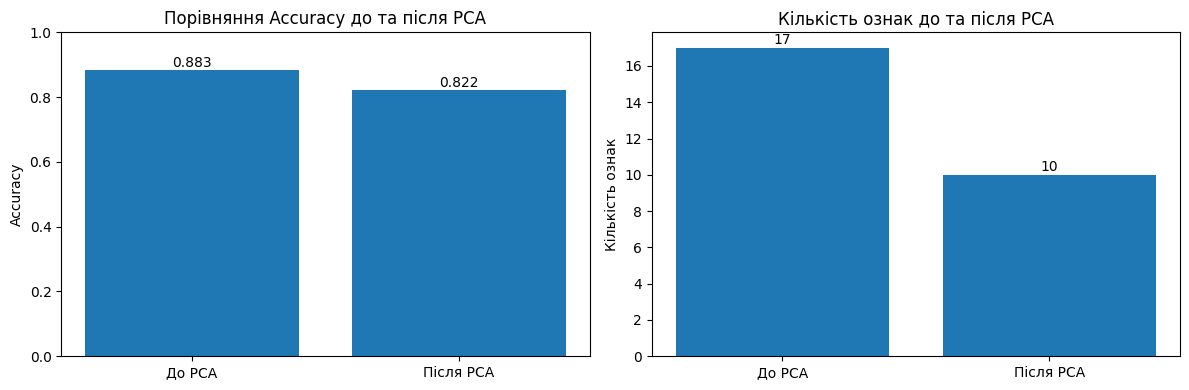

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Порівняння точності
axes[0].bar(
    results_pca['Варіант'],
    results_pca['Accuracy']
)
axes[0].set_title('Порівняння Accuracy до та після PCA')
axes[0].set_ylabel('Accuracy')
axes[0].set_ylim(0, 1)

for i, value in enumerate(results_pca['Accuracy']):
    axes[0].text(i, value + 0.01, f'{value:.3f}', ha='center')

# Порівняння кількості ознак
axes[1].bar(
    results_pca['Варіант'],
    results_pca['Кількість ознак']
)
axes[1].set_title('Кількість ознак до та після PCA')
axes[1].set_ylabel('Кількість ознак')

for i, value in enumerate(results_pca['Кількість ознак']):
    axes[1].text(i, value + 0.2, str(value), ha='center')

plt.tight_layout()
plt.show()

У ході експерименту було досліджено вплив методу головних компонент (PCA) на якість класифікації кіберзагроз за допомогою алгоритму Random Forest. До застосування PCA модель використовувала 17 ознак і досягла точності 88,31%. Після зменшення розмірності до 10 компонент, які зберігають 95,16% дисперсії даних, точність знизилася до 82,23%.

Таким чином, кількість ознак зменшилася на 41,2%, проте якість класифікації погіршилася, а час навчання збільшився з 1,37 до 4,13 секунди. Це свідчить про те, що зменшення розмірності не завжди покращує роботу моделі. У цьому випадку використання початкових ознак забезпечило кращу точність і менший час навчання Random Forest.

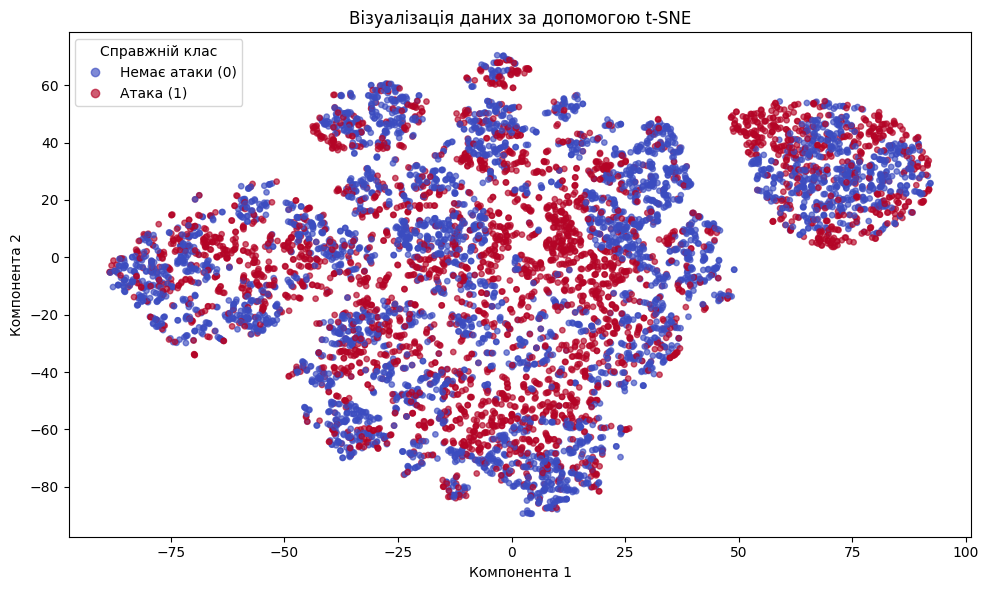

In [10]:
from sklearn.manifold import TSNE

# Перетворюємо дані у двовимірний простір
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    init='pca',
    learning_rate='auto'
)

X_tsne = tsne.fit_transform(X_train_dense)

# Візуалізуємо справжні класи
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=y_train.to_numpy(),
    cmap='coolwarm',
    alpha=0.65,
    s=15
)

plt.title('Візуалізація даних за допомогою t-SNE')
plt.xlabel('Компонента 1')
plt.ylabel('Компонента 2')

plt.legend(
    handles=scatter.legend_elements()[0],
    labels=['Немає атаки (0)', 'Атака (1)'],
    title='Справжній клас'
)

plt.tight_layout()
plt.show()


Для візуалізації даних у двовимірному просторі було застосовано алгоритм t-SNE. На графіку точки позначено відповідно до справжніх класів: звичайні мережеві сесії (0) та атаки (1).

Результати показують, що дані утворюють декілька локальних груп, однак у багатьох із них присутні обидва класи. Це свідчить про те, що ознаки не забезпечують повного розділення атак і звичайних сесій у двовимірному представленні. Водночас t-SNE допомагає виявити локальну структуру даних і наочно дослідити їхню організацію. Слід враховувати, що t-SNE призначений насамперед для візуалізації, а не для оцінювання якості класифікації.

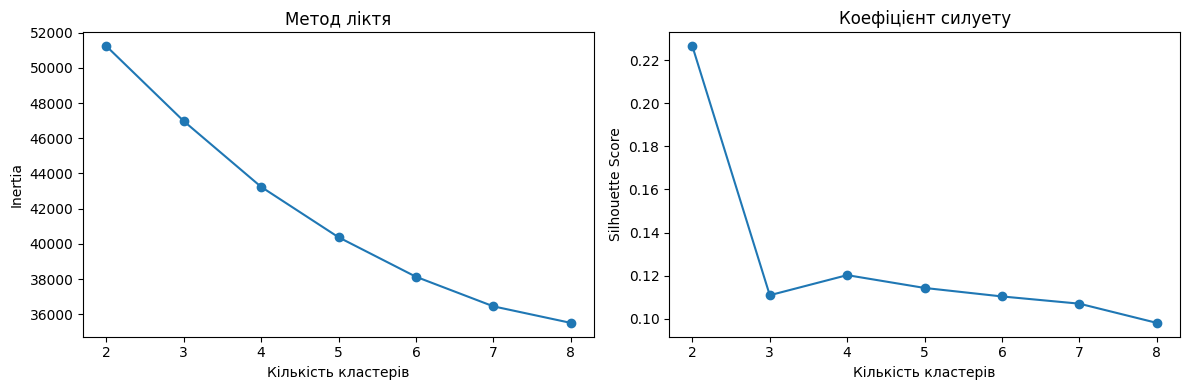

Результати підбору кількості кластерів:
k=2: inertia=51234.22, silhouette=0.2265
k=3: inertia=46973.60, silhouette=0.1109
k=4: inertia=43237.13, silhouette=0.1202
k=5: inertia=40374.18, silhouette=0.1143
k=6: inertia=38130.09, silhouette=0.1103
k=7: inertia=36449.69, silhouette=0.1070
k=8: inertia=35509.38, silhouette=0.0980


In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Перевіряємо кількість кластерів від 2 до 8
k_values = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_train_dense)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_train_dense, cluster_labels)
    )

# Візуалізація методу ліктя та коефіцієнта силуету
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_values, inertias, marker='o')
axes[0].set_title('Метод ліктя')
axes[0].set_xlabel('Кількість кластерів')
axes[0].set_ylabel('Inertia')
axes[0].set_xticks(list(k_values))

axes[1].plot(k_values, silhouette_scores, marker='o')
axes[1].set_title('Коефіцієнт силуету')
axes[1].set_xlabel('Кількість кластерів')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(list(k_values))

plt.tight_layout()
plt.show()

print("Результати підбору кількості кластерів:")
for k, inertia, score in zip(
    k_values, inertias, silhouette_scores
):
    print(f"k={k}: inertia={inertia:.2f}, silhouette={score:.4f}")

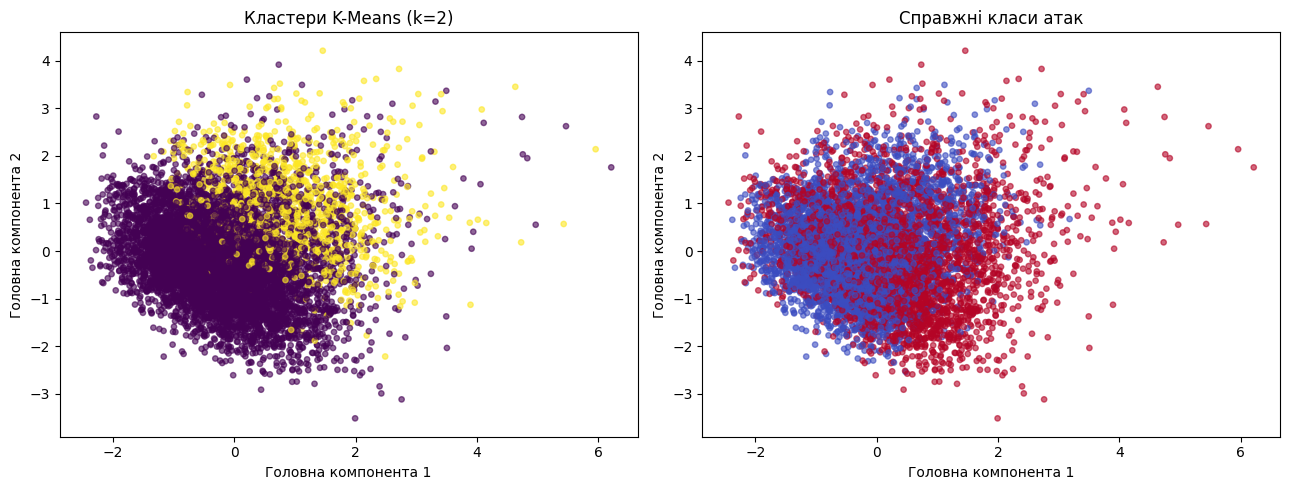

Порівняння кластерів зі справжніми класами:


Справжній клас,0,1
Кластер,,
0,3610,2871
1,608,540


Adjusted Rand Index (ARI): 0.0022


In [12]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
import pandas as pd
import matplotlib.pyplot as plt

# Кластеризація без використання цільової змінної
kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)
clusters = kmeans_final.fit_predict(X_train_dense)

# PCA для візуалізації у двох вимірах
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_train_dense)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    X_pca_2d[:, 0], X_pca_2d[:, 1],
    c=clusters, cmap='viridis', alpha=0.6, s=15
)
axes[0].set_title('Кластери K-Means (k=2)')
axes[0].set_xlabel('Головна компонента 1')
axes[0].set_ylabel('Головна компонента 2')

axes[1].scatter(
    X_pca_2d[:, 0], X_pca_2d[:, 1],
    c=y_train.to_numpy(), cmap='coolwarm', alpha=0.6, s=15
)
axes[1].set_title('Справжні класи атак')
axes[1].set_xlabel('Головна компонента 1')
axes[1].set_ylabel('Головна компонента 2')

plt.tight_layout()
plt.show()

# Порівняння кластерів зі справжніми класами
comparison = pd.crosstab(
    pd.Series(clusters, name='Кластер'),
    pd.Series(y_train.to_numpy(), name='Справжній клас')
)

print("Порівняння кластерів зі справжніми класами:")
display(comparison)

ari = adjusted_rand_score(y_train, clusters)
print(f"Adjusted Rand Index (ARI): {ari:.4f}")

In [13]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

from wordcloud import WordCloud, STOPWORDS
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Завантаження датасету
sms_path = '/content/drive/MyDrive/Colab Notebooks/SMSSpamCollection'

df_sms = pd.read_csv(
    sms_path,
    sep='\t',
    header=None,
    names=['label', 'text'],
    encoding='utf-8'
)

print("Розмір датасету:", df_sms.shape)
print("\nКількість повідомлень за класами:")
print(df_sms['label'].value_counts())
print("\nПропущені значення:")
print(df_sms.isnull().sum())

display(df_sms.head())

Розмір датасету: (5572, 2)

Кількість повідомлень за класами:
label
ham     4825
spam     747
Name: count, dtype: int64

Пропущені значення:
label    0
text     0
dtype: int64


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [14]:
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    words = text.split()
    words = [
        word for word in words
        if word not in ENGLISH_STOP_WORDS
    ]
    return ' '.join(words)

df_sms['clean_text'] = df_sms['text'].apply(preprocess_text)

print("Приклад початкового повідомлення:")
print(df_sms['text'].iloc[0])

print("\nПісля попередньої обробки:")
print(df_sms['clean_text'].iloc[0])

Приклад початкового повідомлення:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Після попередньої обробки:
jurong point crazy available bugis n great world la e buffet cine got amore wat


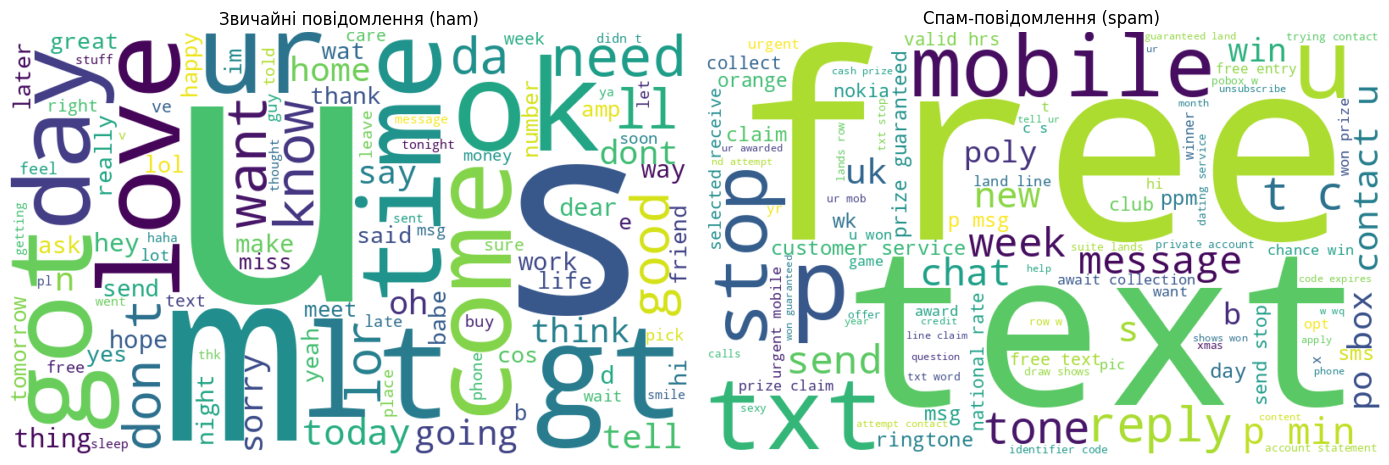

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, label, title in zip(
    axes,
    ['ham', 'spam'],
    ['Звичайні повідомлення (ham)', 'Спам-повідомлення (spam)']
):
    text_data = ' '.join(
        df_sms.loc[df_sms['label'] == label, 'clean_text']
    )

    wordcloud = WordCloud(
        width=800,
        height=500,
        background_color='white',
        stopwords=STOPWORDS,
        max_words=100
    ).generate(text_data)

    ax.imshow(wordcloud, interpolation='bilinear')
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [16]:
# Відокремлюємо текст від цільової мітки
X_sms = df_sms['clean_text']
y_sms = df_sms['label']

# Розділяємо дані зі збереженням пропорцій класів
X_sms_train, X_sms_test, y_sms_train, y_sms_test = train_test_split(
    X_sms,
    y_sms,
    test_size=0.2,
    random_state=42,
    stratify=y_sms
)

# TF-IDF + класифікатор
sms_model = Pipeline([
    ('tfidf', TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=10000
    )),
    ('classifier', MultinomialNB())
])

# Навчання моделі
sms_model.fit(X_sms_train, y_sms_train)

# Прогнозування на тестових даних
y_sms_pred = sms_model.predict(X_sms_test)

print("Розмір навчальної вибірки:", len(X_sms_train))
print("Розмір тестової вибірки:", len(X_sms_test))
print(f"Accuracy: {accuracy_score(y_sms_test, y_sms_pred):.4f}")

print("\nЗвіт класифікації:")
print(classification_report(
    y_sms_test,
    y_sms_pred,
    labels=['ham', 'spam'],
    zero_division=0
))

Розмір навчальної вибірки: 4457
Розмір тестової вибірки: 1115
Accuracy: 0.9668

Звіт класифікації:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.75      0.86       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.96      1115



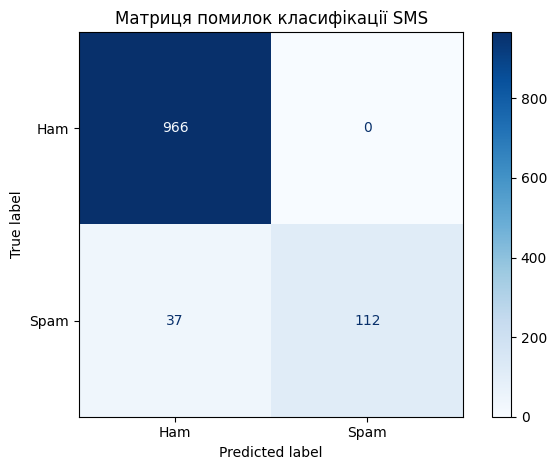

In [17]:
cm = confusion_matrix(
    y_sms_test,
    y_sms_pred,
    labels=['ham', 'spam']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Ham', 'Spam']
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Матриця помилок класифікації SMS')
plt.tight_layout()
plt.show()

**Висновок**

У ході виконання лабораторної роботи було досліджено методи зменшення розмірності даних, кластеризації та класифікації текстової інформації з використанням бібліотеки Scikit-learn.

На першому етапі для набору даних виявлення кіберзагроз було застосовано метод головних компонент (PCA). Кількість ознак зменшилася з 17 до 10 зі збереженням 95,16% дисперсії. Водночас точність класифікатора Random Forest знизилася з 88,31% до 82,23%, а час його навчання збільшився з 1,37 до 4,13 секунди. Це показало, що зменшення розмірності не завжди покращує якість класифікації. Додатково за допомогою t-SNE було візуалізовано дані у двовимірному просторі. На графіку спостерігалося часткове перекриття звичайних мережевих сесій та атак.

На другому етапі було виконано кластеризацію методом K-Means без використання цільової змінної під час побудови кластерів. Для вибору кількості кластерів досліджено значення Inertia та коефіцієнта силуету. Найвище значення Silhouette Score становило 0,2265 при двох кластерах. Однак значення Adjusted Rand Index (ARI) дорівнювало 0,0022, що свідчить про практично відсутню відповідність між отриманими кластерами та справжніми класами атак. Отже, у використаному представленні даних K-Means не зміг відтворити структуру класів кіберзагроз.

На третьому етапі було побудовано класифікатор SMS-повідомлень на основі TF-IDF та алгоритму Multinomial Naive Bayes. Для аналізу текстів створено хмари слів окремо для звичайних повідомлень і спаму. На тестовій вибірці з 1115 повідомлень модель досягла Accuracy 96,68%. Для класу спаму Precision становила 1,00, Recall - 0,75, а F1-score - 0,86. Модель правильно виявила 112 із 149 спам-повідомлень, а 37 повідомлень помилково віднесла до звичайних. Це демонструє високу загальну точність моделі, але вказує на можливість покращення повноти виявлення спаму.

Таким чином, у лабораторній роботі було практично досліджено можливості PCA, t-SNE, K-Means, TF-IDF та наївного байєсівського класифікатора. Отримані результати показали, що ефективність методів залежить від структури даних і поставленого завдання, тому їхню якість необхідно оцінювати за відповідними метриками, а не лише за візуальним представленням або загальною точністю.